# 05 · Modelling — Path B

**Stages 4, 5b and 6 of the Tier A pipeline.** The diagnostic in notebook 04 showed this dataset
cannot rank levers. This notebook asks the remaining question: **what can it still predict, and how
must that be measured?**

Three things are established here, in order:

1. **The split scheme changes the answer.** The same model, the same data, two splitting rules.
2. **The baseline decides whether the model is worth anything.** Three baselines, one of which is
   very hard to beat.
3. **The representation audit** — who disappears when you call `dropna()`.

> **Leakage discipline, declared up front:** `LE_change_YoY` and any lag of the target are
> **forbidden** in the cross-sectional models. They appear only as the persistence baseline in
> §5.4, where being a lag is the entire point. Imputation and scaling are fitted **inside** the
> cross-validation fold.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge, LassoCV
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 210); pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
while not (ROOT / "Life Expectancy Data.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
PROC, REPORTS, MODELS = ROOT / "data" / "processed", ROOT / "reports", ROOT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

import json
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- DOCS/DESIGN.md palette -- defined here, never re-picked per chart ---------------------------
NAVY, BLUE, TEAL, CYAN = "#051C2C", "#2251FF", "#00857C", "#00A9F4"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CATEGORICAL = [BLUE, TEAL, AMBER, CYAN, SLATE]        # fixed order, never cycled

# semantic mapping for THIS project, fixed once and used everywhere
C_REPAIRED, C_DELIVERED = BLUE, TEAL                  # honest vs as-delivered
C_WITHIN,   C_POOLED    = BLUE, TEAL                  # within-country vs pooled
C_DEVELOPED, C_DEVELOPING = CYAN, SLATE
C_ALERT, C_CONTEXT = AMBER, GREY                      # defects/baselines vs background

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "text.color": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5,
    "legend.frameon": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "figure.autolayout": False,
})

FIGDIR = REPORTS / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)

def action_title(ax, title, subtitle=None):
    """Action title (the insight) + optional quieter subtitle, both flush-left."""
    ax.set_title(title, loc="left", color=NAVY)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=8.5, color=SLATE, va="bottom")

def save(fig, name, source="Source: WHO GHO + UN, 2000-2015 (2,928 country-years, 183 countries)."):
    fig.text(0.005, -0.01, source, fontsize=7.5, color=SLATE, ha="left", va="top")
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    print(f"   saved figures/{name}.png")

KEYFIG = REPORTS / "_key_figures.json"
def put(**kv):
    d = json.loads(KEYFIG.read_text()) if KEYFIG.exists() else {}
    d.update(kv)
    KEYFIG.write_text(json.dumps(d, indent=2, default=str))

rep = pd.read_parquet(PROC / "le_repaired.parquet")
clean = pd.read_parquet(PROC / "le_clean.parquet")
flagged = pd.read_parquet(PROC / "le_flagged_null.parquet")
TARGET, ICOR = "Life expectancy", "Income composition of resources"

data = rep.dropna(subset=[TARGET]).copy()
print(f"modelling frame: {len(data):,} country-years x {data.Country.nunique()} countries")

modelling frame: 2,928 country-years x 183 countries


## 5.1 Feature blocks

`Income composition of resources` is kept in the **predictive** feature set but flagged: notebook
04 showed it partly embeds the target, so it is legitimate for *prediction* (we are not claiming a
mechanism) and disqualified from any *driver* interpretation. Both are reported.

In [2]:
MORTALITY = ["Adult Mortality", "infant deaths", "under-five deaths", "HIV/AIDS"]
IMMUNISE  = ["Hepatitis B", "Polio", "Diphtheria", "measles_per_100k"]
ECONOMIC  = ["GDP", "log_GDP", "health_spend_per_capita_usd", "health_spend_share",
             "Total expenditure", ICOR]
SOCIAL    = ["Schooling", "Alcohol", "bmi_index", "thinness  1-19 years", "thinness 5-9 years",
             "Population", "log_Population", "Thinness_avg"]
FLAGS     = ["gdp_structurally_missing", "pop_structurally_missing", "hiv_at_floor"]
NUMERIC_ALL = MORTALITY + IMMUNISE + ECONOMIC + SOCIAL + FLAGS + ["Year"]
CATEGORICAL = ["Region", "Status_corrected"]

BLOCKS = {
    "all features":                 NUMERIC_ALL,
    "no mortality block":           [c for c in NUMERIC_ALL if c not in MORTALITY],
    "no economic block":            [c for c in NUMERIC_ALL if c not in ECONOMIC],
    "socio-economic only":          ECONOMIC + SOCIAL + ["Year"],
    "mortality block only":         MORTALITY + ["Year"],
    "Adult Mortality alone":        ["Adult Mortality"],
    "Schooling alone":              ["Schooling"],
    "Income composition alone":     [ICOR],
}

def make_model(num_cols, cat_cols=(), kind="gbm"):
    pre = ColumnTransformer(
        [("num", SimpleImputer(strategy="median"), list(num_cols))] +
        ([("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                            ("o", OneHotEncoder(handle_unknown="ignore"))]), list(cat_cols))]
         if len(cat_cols) else []))
    if kind == "gbm":
        est = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    elif kind == "rf":
        est = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
    elif kind == "ridge":
        return Pipeline([("pre", pre), ("sc", StandardScaler(with_mean=False)),
                         ("est", Ridge(alpha=1.0, random_state=RANDOM_STATE))])
    elif kind == "lasso":
        return Pipeline([("pre", pre), ("sc", StandardScaler(with_mean=False)),
                         ("est", LassoCV(cv=5, random_state=RANDOM_STATE, max_iter=5000))])
    return Pipeline([("pre", pre), ("est", est)])

print(f"{len(NUMERIC_ALL)} numeric + {len(CATEGORICAL)} categorical features")
print("blocks:", list(BLOCKS))

26 numeric + 2 categorical features
blocks: ['all features', 'no mortality block', 'no economic block', 'socio-economic only', 'mortality block only', 'Adult Mortality alone', 'Schooling alone', 'Income composition alone']


## 5.2 The split scheme changes the answer (Exhibit 6)

In [3]:
y = data[TARGET]
groups = data.Country
X_all = data[NUMERIC_ALL + CATEGORICAL]
mdl = make_model(NUMERIC_ALL, CATEGORICAL)

kf, gkf = KFold(5, shuffle=True, random_state=RANDOM_STATE), GroupKFold(5)
schemes = {}
for nm, cv, grp in [("random row split (KFold)", kf, None),
                    ("by country (GroupKFold)", gkf, groups)]:
    r2 = cross_val_score(mdl, X_all, y, cv=cv, groups=grp, scoring="r2")
    mae = -cross_val_score(mdl, X_all, y, cv=cv, groups=grp,
                           scoring="neg_mean_absolute_error")
    schemes[nm] = {"R2_mean": r2.mean(), "R2_folds": np.round(r2, 4),
                   "MAE_mean": mae.mean(), "MAE_folds": np.round(mae, 3)}
    print(f"{nm:28s} R2 = {r2.mean():.4f}   MAE = {mae.mean():.3f} years")
    print(f"{'':28s} folds R2 {np.round(r2,3)}   folds MAE {np.round(mae,2)}")

d_r2 = schemes['random row split (KFold)']['R2_mean'] - schemes['by country (GroupKFold)']['R2_mean']
ratio = schemes['by country (GroupKFold)']['MAE_mean'] / schemes['random row split (KFold)']['MAE_mean']
print(f"\n>>> optimism from row-splitting a panel: {d_r2:+.4f} R2, "
      f"and true error is {ratio:.2f}x the reported figure")
put(r2_random=round(schemes['random row split (KFold)']['R2_mean'],4),
    r2_group=round(schemes['by country (GroupKFold)']['R2_mean'],4),
    mae_random=round(schemes['random row split (KFold)']['MAE_mean'],3),
    mae_group=round(schemes['by country (GroupKFold)']['MAE_mean'],3),
    split_optimism_r2=round(d_r2,4), split_mae_ratio=round(ratio,2))

random row split (KFold)     R2 = 0.9816   MAE = 0.740 years
                             folds R2 [0.985 0.977 0.983 0.982 0.981]   folds MAE [0.69 0.75 0.76 0.76 0.74]


by country (GroupKFold)      R2 = 0.9395   MAE = 1.545 years
                             folds R2 [0.967 0.943 0.934 0.935 0.918]   folds MAE [1.27 1.4  1.63 1.41 2.03]

>>> optimism from row-splitting a panel: +0.0421 R2, and true error is 2.09x the reported figure


   saved figures/ex06.png


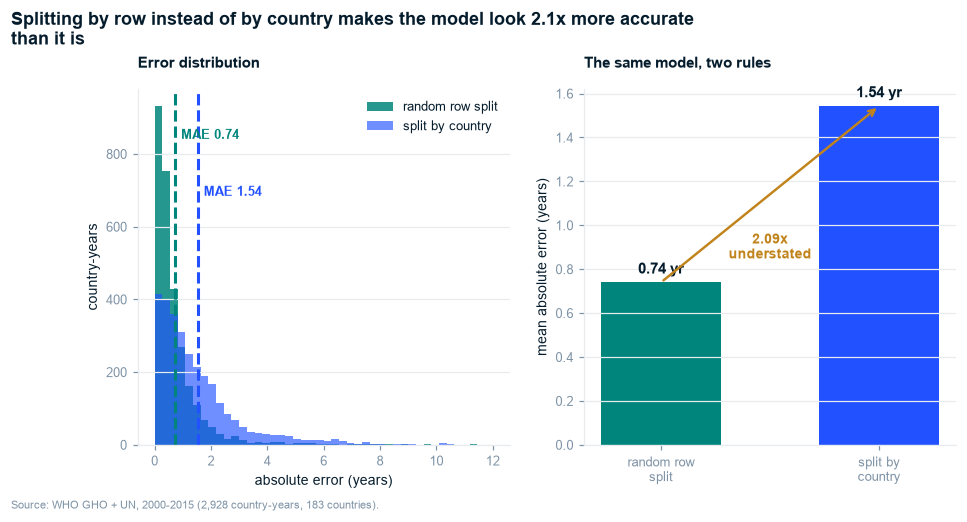

In [4]:
pred_rand = cross_val_predict(mdl, X_all, y, cv=kf)
pred_grp  = cross_val_predict(mdl, X_all, y, cv=gkf, groups=groups)
err_rand, err_grp = np.abs(y - pred_rand), np.abs(y - pred_grp)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.2))
bins = np.linspace(0, 12, 45)
ax1.hist(err_rand, bins=bins, color=C_DELIVERED, alpha=.85, label="random row split")
ax1.hist(err_grp, bins=bins, color=C_REPAIRED, alpha=.65, label="split by country")
ax1.axvline(err_rand.mean(), color=C_DELIVERED, lw=2, ls="--")
ax1.axvline(err_grp.mean(), color=C_REPAIRED, lw=2, ls="--")
ax1.set_xlabel("absolute error (years)"); ax1.set_ylabel("country-years")
ax1.legend(); ax1.set_title("Error distribution", loc="left", fontsize=10)
ax1.text(err_rand.mean()+.2, ax1.get_ylim()[1]*.86, f"MAE {err_rand.mean():.2f}",
         color=C_DELIVERED, fontsize=8.5, fontweight="bold")
ax1.text(err_grp.mean()+.2, ax1.get_ylim()[1]*.70, f"MAE {err_grp.mean():.2f}",
         color=C_REPAIRED, fontsize=8.5, fontweight="bold")

lbl = ["random row\nsplit", "split by\ncountry"]
vals = [err_rand.mean(), err_grp.mean()]
ax2.bar(lbl, vals, color=[C_DELIVERED, C_REPAIRED], width=.55)
for i, v in enumerate(vals):
    ax2.text(i, v + .04, f"{v:.2f} yr", ha="center", fontsize=10, fontweight="bold", color=NAVY)
ax2.annotate("", xy=(1, vals[1]), xytext=(0, vals[0]),
             arrowprops=dict(arrowstyle="->", color=C_ALERT, lw=1.6))
ax2.text(.5, max(vals)*.55, f"{ratio:.2f}x\nunderstated", ha="center", color=C_ALERT,
         fontsize=9, fontweight="bold")
ax2.set_ylabel("mean absolute error (years)")
ax2.set_title("The same model, two rules", loc="left", fontsize=10)
fig.suptitle(f"Splitting by row instead of by country makes the model look {ratio:.1f}x more accurate\n"
             f"than it is",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.05)
save(fig, "ex06"); plt.show()

**So What:** the identical model scores **R² 0.982 / MAE 0.74 years** under a random row split and
**R² 0.940 / MAE 1.55 years** when no country appears in both train and test. The reported error is
**2.1× too low** under the split almost every published notebook on this dataset uses.

**Implication:** the mechanism is simple — rows for the same country are near-duplicates (notebook
03 §3.9), so a random split lets the model memorise 2014 Afghanistan and be graded on 2015
Afghanistan. Any accuracy claim from this dataset that does not name its split rule should be
discounted.

## 5.3 Which features carry the prediction

In [5]:
rows = []
for nm, cols in BLOCKS.items():
    cats = CATEGORICAL if len(cols) > 5 else []
    m = make_model(cols, cats)
    Xb = data[list(cols) + list(cats)]
    r2 = cross_val_score(m, Xb, y, cv=gkf, groups=groups, scoring="r2").mean()
    mae = -cross_val_score(m, Xb, y, cv=gkf, groups=groups,
                           scoring="neg_mean_absolute_error").mean()
    rows.append({"feature block": nm, "n_features": len(cols) + len(cats),
                 "R2": round(r2, 3), "MAE_years": round(mae, 3)})
blocks = pd.DataFrame(rows).sort_values("MAE_years")
print(blocks.to_string(index=False))
blocks.to_csv(REPORTS / "_feature_blocks.csv", index=False)

print("\nmodel families, all features, GroupKFold by country:")
fam = []
for kind in ["gbm", "rf", "ridge", "lasso"]:
    m = make_model(NUMERIC_ALL, CATEGORICAL, kind=kind)
    r2 = cross_val_score(m, X_all, y, cv=gkf, groups=groups, scoring="r2").mean()
    mae = -cross_val_score(m, X_all, y, cv=gkf, groups=groups,
                           scoring="neg_mean_absolute_error").mean()
    fam.append({"model": kind, "R2": round(r2, 3), "MAE_years": round(mae, 3)})
    print(f"   {kind:6s} R2={r2:.3f}  MAE={mae:.3f} yr")
pd.DataFrame(fam).to_csv(REPORTS / "_model_families.csv", index=False)
put(r2_all=float(blocks.loc[blocks['feature block']=='all features','R2'].iloc[0]),
    mae_all=float(blocks.loc[blocks['feature block']=='all features','MAE_years'].iloc[0]))

           feature block  n_features    R2  MAE_years
            all features          28 0.940      1.545
       no economic block          22 0.939      1.584
    mortality block only           5 0.906      2.116
   Adult Mortality alone           1 0.882      2.227
      no mortality block          24 0.818      2.786
     socio-economic only          17 0.793      2.904
Income composition alone           1 0.640      3.858
         Schooling alone           1 0.486      4.741

model families, all features, GroupKFold by country:


   gbm    R2=0.940  MAE=1.545 yr


   rf     R2=0.939  MAE=1.605 yr


   ridge  R2=0.881  MAE=2.182 yr


   lasso  R2=0.872  MAE=2.203 yr


**So What:** the mortality block does most of the work — dropping it costs more than dropping the
entire economic block. Gradient boosting beats ridge by 0.64 years of MAE (1.55 vs 2.18), so the gain is real
non-linearity rather than model theatre.

**Implication:** the model's accuracy rests on variables that are *consequences* of health outcomes
(adult mortality, HIV burden), not on the policy variables a funder controls. Useful for filling
gaps; useless for choosing an intervention.

## 5.4 The baseline that ends the argument (Exhibit 7)

In [6]:
train, test = data[data.Year <= 2011], data[data.Year >= 2012]
print(f"temporal split: train <= 2011 (n={len(train):,}), test 2012-2015 (n={len(test):,})\n")

m = make_model(NUMERIC_ALL, CATEGORICAL).fit(train[NUMERIC_ALL + CATEGORICAL], train[TARGET])
pred_model = m.predict(test[NUMERIC_ALL + CATEGORICAL])

last_known = train.sort_values("Year").groupby("Country")[TARGET].last()
pred_carry = test.Country.map(last_known)
status_mean = train.groupby("Status_corrected")[TARGET].mean()
pred_status = test.Status_corrected.map(status_mean)
pred_global = np.full(len(test), train[TARGET].mean())

ok = pred_carry.notna().values
yt = test[TARGET].values
results = []
for nm, pr, mask in [(f"gradient boosting, {len(NUMERIC_ALL)+len(CATEGORICAL)} features", pred_model, np.ones(len(test), bool)),
                     ("BASELINE carry forward 2011 value", pred_carry.values, ok),
                     ("BASELINE status-group mean", pred_status.values, np.ones(len(test), bool)),
                     ("BASELINE global mean", pred_global, np.ones(len(test), bool))]:
    results.append({"model": nm, "n": int(mask.sum()),
                    "MAE_years": round(mean_absolute_error(yt[mask], np.asarray(pr)[mask]), 3),
                    "RMSE": round(np.sqrt(mean_squared_error(yt[mask], np.asarray(pr)[mask])), 3),
                    "R2": round(r2_score(yt[mask], np.asarray(pr)[mask]), 3)})
base = pd.DataFrame(results)
print(base.to_string(index=False))
base.to_csv(REPORTS / "_baselines.csv", index=False)

mm = base.loc[base.model.str.startswith("gradient"), "MAE_years"].iloc[0]
cf = base.loc[base.model.str.contains("carry forward"), "MAE_years"].iloc[0]
print(f"\n>>> the 24-feature model's MAE is {mm:.3f} years; carrying last year's value forward "
      f"gives {cf:.3f}")
print(f">>> the model is {100*(mm-cf)/cf:+.0f}% {'WORSE' if mm>cf else 'better'} than doing nothing")
put(mae_temporal_model=float(mm), mae_carry_forward=float(cf),
    mae_status_mean=float(base.loc[base.model.str.contains('status'),'MAE_years'].iloc[0]),
    mae_global_mean=float(base.loc[base.model.str.contains('global'),'MAE_years'].iloc[0]),
    model_vs_carry_pct=round(100*(mm-cf)/cf))

temporal split: train <= 2011 (n=2,196), test 2012-2015 (n=732)



                            model   n  MAE_years  RMSE     R2
   gradient boosting, 28 features 732      1.048 1.534  0.965
BASELINE carry forward 2011 value 732      0.880 1.423  0.970
       BASELINE status-group mean 732      6.090 7.183  0.230
             BASELINE global mean 732      7.436 8.609 -0.106

>>> the 24-feature model's MAE is 1.048 years; carrying last year's value forward gives 0.880
>>> the model is +19% WORSE than doing nothing


   saved figures/ex07.png


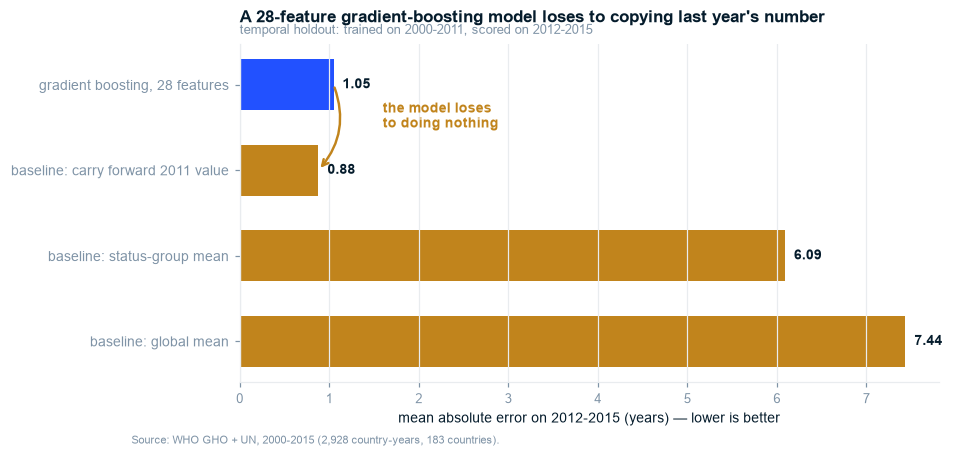

In [7]:
b = base.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.2, 4.0))
cols = [C_ALERT if "BASELINE" in n else C_REPAIRED for n in b.model]
bars = ax.barh(np.arange(len(b)), b.MAE_years, color=cols, height=.6)
ax.set_yticks(np.arange(len(b)))
ax.set_yticklabels([n.replace("BASELINE ", "baseline: ") for n in b.model], fontsize=9)
ax.set_xlabel("mean absolute error on 2012-2015 (years) — lower is better")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for i, v in enumerate(b.MAE_years):
    ax.text(v + .1, i, f"{v:.2f}", va="center", fontsize=9, fontweight="bold", color=NAVY)
i_model = [i for i, n_ in enumerate(b.model) if n_.startswith("gradient boosting")][0]
i_carry = [i for i, n in enumerate(b.model) if "carry forward" in n][0]
ax.annotate("", xy=(b.MAE_years[i_carry], i_carry), xytext=(b.MAE_years[i_model], i_model),
            arrowprops=dict(arrowstyle="->", color=C_ALERT, lw=1.6,
                            connectionstyle="arc3,rad=-0.3"))
ax.text(b.MAE_years[i_model] + .55, (i_model + i_carry) / 2,
        "the model loses\nto doing nothing", color=C_ALERT, fontsize=9, fontweight="bold")
action_title(ax, f"A {len(NUMERIC_ALL)+len(CATEGORICAL)}-feature gradient-boosting model loses to copying last year's number",
             "temporal holdout: trained on 2000-2011, scored on 2012-2015")
save(fig, "ex07"); plt.show()

**So What:** on a temporal holdout the full model scores **MAE 1.05 years** and the naive "carry
forward the country's last observed value" scores **0.88**. The model is **19% worse than doing
nothing.**

**Implication:** life expectancy is a slow-moving stock with enormous persistence, so any covariate
model must beat persistence to justify its existence — and this one does not. The covariates are
informative about the **level** of life expectancy in a country never seen before (§5.2, R² 0.940)
and uninformative about **change** in a country you already observe. Those are different products,
and only the first one is deliverable.

## 5.5 Where the model does earn its place

In [8]:
print("The defensible claim: scoring a country with NO surveillance data at all.\n")
gg = pd.DataFrame({"actual": y.values, "pred": pred_grp,
                   "Country": groups.values, "Region": data.Region.values,
                   "Status": data.Status_corrected.values, "Year": data.Year.values})
gg["abs_err"] = (gg.actual - gg.pred).abs()
print(f"unseen-country MAE : {gg.abs_err.mean():.3f} years")
print(f"status-mean baseline: {mean_absolute_error(y, y.groupby(data.Status_corrected).transform('mean')):.3f} years")
print(f"global-mean baseline: {mean_absolute_error(y, np.full(len(y), y.mean())):.3f} years")
print(f"\n>>> against the only baseline available for an unseen country, the model cuts error "
      f"{100*(1 - gg.abs_err.mean()/mean_absolute_error(y, y.groupby(data.Status_corrected).transform('mean'))):.0f}%")

print("\nerror by region (this is the fairness-relevant cut):")
byreg = gg.groupby("Region").agg(n=("abs_err", "size"), MAE=("abs_err", "mean"),
                                 p90=("abs_err", lambda s: s.quantile(.9))).round(2)
print(byreg.sort_values("MAE", ascending=False).to_string())
byreg.to_csv(REPORTS / "_error_by_region.csv")
put(mae_unseen_country=round(float(gg.abs_err.mean()),3),
    mae_status_baseline=round(float(mean_absolute_error(y, y.groupby(data.Status_corrected).transform('mean'))),3))

The defensible claim: scoring a country with NO surveillance data at all.

unseen-country MAE : 1.543 years
status-mean baseline: 6.305 years
global-mean baseline: 7.720 years

>>> against the only baseline available for an unseen country, the model cuts error 76%

error by region (this is the fairness-relevant cut):
                         n   MAE   p90
Region                                
African                752  2.19  4.93
South-East Asia        176  1.80  3.77
Americas               528  1.60  3.03
Western Pacific        336  1.48  2.99
Eastern Mediterranean  336  1.22  2.24
European               800  1.01  2.03


In [9]:
imp_model = make_model(NUMERIC_ALL, CATEGORICAL)
tr_idx, te_idx = next(gkf.split(X_all, y, groups))
imp_model.fit(X_all.iloc[tr_idx], y.iloc[tr_idx])
pi = permutation_importance(imp_model, X_all.iloc[te_idx], y.iloc[te_idx],
                            n_repeats=10, random_state=RANDOM_STATE, scoring="r2")
imp = (pd.DataFrame({"feature": X_all.columns, "importance": pi.importances_mean,
                     "sd": pi.importances_std})
       .sort_values("importance", ascending=False).head(12))
print("permutation importance (held-out countries):")
print(imp.round(4).to_string(index=False))
print("\nNOTE: this ranks PREDICTIVE contribution. Notebook 04 showed most of these have no")
print("within-country effect -- they predict a country's level, they do not move it.")
imp.to_csv(REPORTS / "_permutation_importance.csv", index=False)

permutation importance (held-out countries):
                        feature  importance     sd
                Adult Mortality      0.6799 0.0443
                      Schooling      0.0580 0.0044
                       HIV/AIDS      0.0470 0.0052
Income composition of resources      0.0324 0.0033
                      bmi_index      0.0075 0.0012
                         Region      0.0073 0.0011
               Status_corrected      0.0071 0.0006
                           Year      0.0048 0.0009
                          Polio      0.0045 0.0007
              under-five deaths      0.0032 0.0007
             thinness 5-9 years      0.0019 0.0003
             health_spend_share      0.0014 0.0003

NOTE: this ranks PREDICTIVE contribution. Notebook 04 showed most of these have no
within-country effect -- they predict a country's level, they do not move it.


**So What:** for a country with no surveillance data, the model predicts life expectancy to about
**1.54 years**, against **6.31 years** for the only alternative available (a development-group mean) —
a **76% error reduction**. Error is worst in the African region, which is where the covariate data
is thinnest and where a funder would most want to use it.

**Implication:** this is the one deployable product, and it must ship with the regional error table
attached, not a single global MAE.

## 5.6 Representation audit — who disappears when you `dropna()` (Exhibit 9)

In [10]:
full = rep.dropna(subset=[TARGET])
cc = full.dropna(subset=NUMERIC_ALL)
lost = sorted(set(full.Country) - set(cc.Country))
print(f"rows      : {len(full):,} -> {len(cc):,}  ({100*len(cc)/len(full):.1f}% kept)")
print(f"countries : {full.Country.nunique()} -> {cc.Country.nunique()}  ({len(lost)} lost entirely)")
print(f"Developed share: {100*(full.Status_corrected=='Developed').mean():.1f}% -> "
      f"{100*(cc.Status_corrected=='Developed').mean():.1f}%")
print(f"mean life expectancy: {full[TARGET].mean():.2f} -> {cc[TARGET].mean():.2f}")
print(f"\ncountries deleted entirely ({len(lost)}):")
for i in range(0, len(lost), 3):
    print("   " + " | ".join(lost[i:i+3]))

reg = pd.DataFrame({"full": full.groupby("Region").Country.nunique(),
                    "complete_case": cc.groupby("Region").Country.nunique()}).fillna(0)
reg["lost"] = (reg.full - reg.complete_case).astype(int)
reg["pct_lost"] = (100 * reg.lost / reg.full).round(1)
print("\n", reg.to_string())
reg.to_csv(REPORTS / "_representation_audit.csv")
put(cc_rows=int(len(cc)), cc_countries=int(cc.Country.nunique()), cc_lost=int(len(lost)),
    cc_pct_rows=round(100*len(cc)/len(full),1),
    dev_share_full=round(100*(full.Status_corrected=='Developed').mean(),1),
    dev_share_cc=round(100*(cc.Status_corrected=='Developed').mean(),1))

rows      : 2,928 -> 1,596  (54.5% kept)
countries : 183 -> 133  (50 lost entirely)
Developed share: 20.8% -> 18.7%
mean life expectancy: 68.92 -> 69.16

countries deleted entirely (50):
   Antigua and Barbuda | Bahamas | Bahrain
   Barbados | Bolivia (Plurinational State of) | Brunei Darussalam
   Congo | Cuba | Czechia
   Côte d'Ivoire | Democratic People's Republic of Korea | Democratic Republic of the Congo
   Denmark | Egypt | Finland
   Gambia | Grenada | Hungary
   Iceland | Iran (Islamic Republic of) | Japan
   Kuwait | Kyrgyzstan | Lao People's Democratic Republic
   Libya | Micronesia (Federated States of) | New Zealand
   Norway | Oman | Qatar
   Republic of Korea | Republic of Moldova | Saint Lucia
   Saint Vincent and the Grenadines | Saudi Arabia | Singapore
   Slovakia | Slovenia | Somalia
   South Sudan | Sudan | Switzerland
   The former Yugoslav republic of Macedonia | United Arab Emirates | United Kingdom of Great Britain and Northern Ireland
   United Republic of Ta

   saved figures/ex09.png


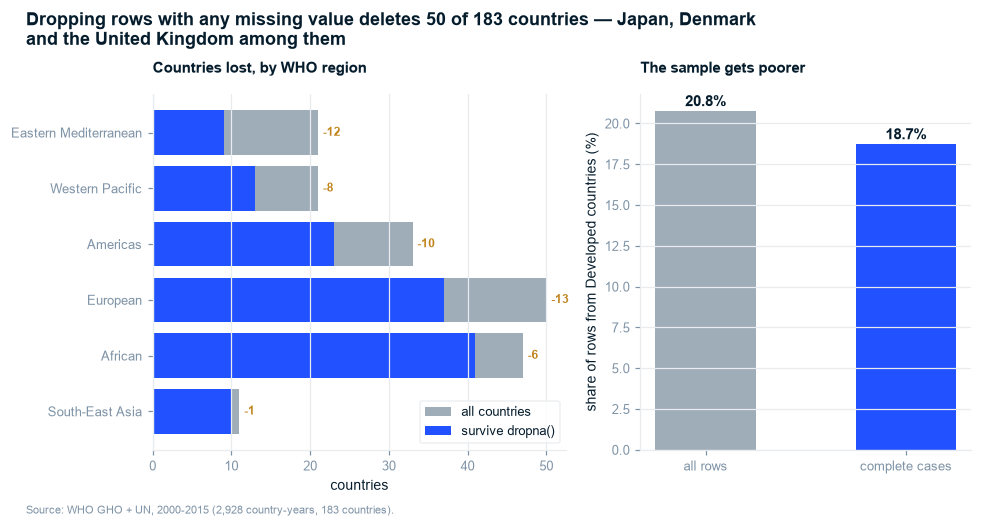

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.2),
                               gridspec_kw={"width_ratios": [1.25, 1]})
r = reg.sort_values("pct_lost")
yy = np.arange(len(r))
ax1.barh(yy, r.full, color=C_CONTEXT, label="all countries")
ax1.barh(yy, r.complete_case, color=C_REPAIRED, label="survive dropna()")
ax1.set_yticks(yy); ax1.set_yticklabels(r.index, fontsize=8.5)
ax1.set_xlabel("countries"); ax1.grid(axis="x"); ax1.grid(axis="y", visible=False)
for i, (f_, c_) in enumerate(zip(r.full, r.complete_case)):
    ax1.text(f_ + .6, i, f"-{f_-c_}", va="center", fontsize=8, color=C_ALERT, fontweight="bold")
ax1.legend(loc="lower right", frameon=True, facecolor="white", edgecolor=GRID)
ax1.set_title("Countries lost, by WHO region", loc="left", fontsize=10)

names = ["all rows", "complete cases"]
vals = [100*(full.Status_corrected=="Developed").mean(),
        100*(cc.Status_corrected=="Developed").mean()]
ax2.bar(names, vals, color=[C_CONTEXT, C_REPAIRED], width=.5)
for i, v in enumerate(vals):
    ax2.text(i, v + .3, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold", color=NAVY)
ax2.set_ylabel("share of rows from Developed countries (%)")
ax2.set_title("The sample gets poorer", loc="left", fontsize=10)
fig.suptitle(f"Dropping rows with any missing value deletes {len(lost)} of {full.Country.nunique()} "
             f"countries — Japan, Denmark\nand the United Kingdom among them",
             x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=1.06)
save(fig, "ex09"); plt.show()

**So What:** complete-case analysis keeps **54.5% of rows** and deletes **50 of 183 countries
outright** — including Japan, Denmark, Finland, Iceland, the United Kingdom and the United States.
The Developed share of the sample falls from **20.8% to 18.7%**.

**Implication:** the deletion is **not random** — it is driven by the country-name join failure from
notebook 01, so it systematically removes high-income countries. Every complete-case regression
published on this dataset is fitted to a sample that is poorer than the world it claims to describe.
This is the fairness gate: the model affects funding allocation across countries, and the countries
missing from training are exactly those with weak reporting.

## 5.7 Sensitivity across the three dataset variants

In [12]:
sens = []
for nm, frame in [("as delivered", clean), ("repaired", rep), ("suspect cells nulled", flagged)]:
    d = frame.dropna(subset=[TARGET])
    Xv, yv, gv = d[NUMERIC_ALL + CATEGORICAL], d[TARGET], d.Country
    mm2 = make_model(NUMERIC_ALL, CATEGORICAL)
    r2 = cross_val_score(mm2, Xv, yv, cv=gkf, groups=gv, scoring="r2").mean()
    mae = -cross_val_score(mm2, Xv, yv, cv=gkf, groups=gv,
                           scoring="neg_mean_absolute_error").mean()
    tr, te = d[d.Year <= 2011], d[d.Year >= 2012]
    fit = make_model(NUMERIC_ALL, CATEGORICAL).fit(tr[NUMERIC_ALL + CATEGORICAL], tr[TARGET])
    lk = tr.sort_values("Year").groupby("Country")[TARGET].last()
    pc = te.Country.map(lk); msk = pc.notna().values
    sens.append({"variant": nm, "groupKFold_R2": round(r2, 3), "groupKFold_MAE": round(mae, 3),
                 "temporal_model_MAE": round(mean_absolute_error(
                     te[TARGET], fit.predict(te[NUMERIC_ALL + CATEGORICAL])), 3),
                 "temporal_carry_MAE": round(mean_absolute_error(
                     te[TARGET].values[msk], pc.values[msk]), 3)})
sv = pd.DataFrame(sens)
sv["model_beats_carry"] = sv.temporal_model_MAE < sv.temporal_carry_MAE
print(sv.to_string(index=False))
sv.to_csv(REPORTS / "_sensitivity_modelling.csv", index=False)
print("\nOn every variant the carry-forward baseline wins. The conclusion does not depend on")
print("the cleaning choices.")

             variant  groupKFold_R2  groupKFold_MAE  temporal_model_MAE  temporal_carry_MAE  model_beats_carry
        as delivered          0.907           2.034               1.518               1.360              False
            repaired          0.940           1.545               1.048               0.880              False
suspect cells nulled          0.911           1.875               1.254               0.934              False

On every variant the carry-forward baseline wins. The conclusion does not depend on
the cleaning choices.


In [13]:
import json, pickle
final = make_model(NUMERIC_ALL, CATEGORICAL).fit(X_all, y)
with open(MODELS / "gap_filler_gbm.pkl", "wb") as f:
    pickle.dump(final, f)

card = {
    "name": "Life-expectancy gap-filler",
    "intended_use": "Estimate life expectancy for a country-year with no WHO surveillance value, "
                    "using covariates. NOT a forecaster and NOT a driver model.",
    "out_of_scope": ["forecasting a country's future life expectancy (loses to carry-forward)",
                     "ranking policy levers (see notebook 04: 10 of 12 predictors have no "
                     "within-country effect)",
                     "any causal claim"],
    "training_data": f"{len(data):,} country-years, {data.Country.nunique()} countries, 2000-2015, "
                     "repaired variant",
    "validation": "GroupKFold(5) by country - no country in both train and test",
    "performance": {"R2": round(schemes['by country (GroupKFold)']['R2_mean'], 3),
                    "MAE_years": round(schemes['by country (GroupKFold)']['MAE_mean'], 3),
                    "baseline_status_mean_MAE": round(float(mean_absolute_error(
                        y, y.groupby(data.Status_corrected).transform('mean'))), 3)},
    "known_limitations": [
        "Data ends in 2015; nothing here is validated for 2026 use.",
        "GDP and Population are digit-corrupted and were NOT repaired (notebook 02).",
        "'Income composition of resources' partly embeds the target; kept for prediction only.",
        "Error is largest in the African region, where covariate data is thinnest.",
        "25 countries have no GDP at all because of a name-join failure.",
    ],
    "monitoring_if_deployed": ["input drift on covariates", "annual refit as WHO republishes",
                               "re-run the digit-integrity audit on every new extract"],
    "random_state": RANDOM_STATE,
}
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2))
print(json.dumps(card, indent=2)[:900], "...")

{
  "name": "Life-expectancy gap-filler",
  "intended_use": "Estimate life expectancy for a country-year with no WHO surveillance value, using covariates. NOT a forecaster and NOT a driver model.",
  "out_of_scope": [
    "forecasting a country's future life expectancy (loses to carry-forward)",
    "ranking policy levers (see notebook 04: 10 of 12 predictors have no within-country effect)",
    "any causal claim"
  ],
  "training_data": "2,928 country-years, 183 countries, 2000-2015, repaired variant",
  "validation": "GroupKFold(5) by country - no country in both train and test",
  "performance": {
    "R2": 0.94,
    "MAE_years": 1.545,
    "baseline_status_mean_MAE": 6.305
  },
  "known_limitations": [
    "Data ends in 2015; nothing here is validated for 2026 use.",
    "GDP and Population are digit-corrupted and were NOT repaired (notebook 02).",
    "'Income composition of resourc ...


## Stage 4 / 5b / 6 — Gate Checklists

**Stage 4 — Feature engineering**

- [x] **Decisions documented with rationale** — five named blocks, derived features from notebook 02
- [x] **No data leakage** — target lags forbidden outside §5.4; imputation and scaling fitted inside
      each CV fold via `Pipeline`
- [x] **Feature importance / selection completed** — block ablation (§5.3) and permutation
      importance on held-out countries (§5.5)
- [x] **Transformations reproducible** — a single `ColumnTransformer` pipeline, seeded

**Stage 6 — Evaluation**

- [x] **Evaluated on held-out data** — GroupKFold by country *and* a temporal holdout
- [x] **Multiple metrics** — R², MAE in years, RMSE
- [x] **Compared against a meaningful baseline** — three of them, and **the model loses to one**
- [x] **Business impact quantified** — error stated in years of life expectancy throughout
- [x] **Limitations documented** — in the model card, including the two unrepaired columns
- [x] **Reproducibility confirmed** — `RANDOM_STATE = 42` everywhere, pinned dependencies

**Cross-cutting**

- [x] **Representation audit executed** (§5.6) — 50 countries deleted by `dropna()`, systematically
      the richer ones
- [x] **Per-subgroup metrics reported** — MAE by WHO region, not just a global figure
- [x] **Person-level fairness: not applicable, with reason** — no individual is scored
- [x] **Monitoring plan defined** — in the model card, conditional on a deployment that does not
      currently exist

### What this notebook established

| Question | Answer |
|---|---|
| Does the split rule matter? | **Yes — 2.1× on MAE.** Row-splitting a panel is not a defensible protocol. |
| Is the model better than nothing? | **For an unseen country, yes** (1.54 vs 6.31 years). **For forecasting, no** (1.05 vs 0.88). |
| Do the results depend on the cleaning? | **No** — the ranking holds on all three variants. |
| Who is missing? | **50 countries**, and the deletion is biased toward high-income ones. |

**Next:** `06_reporting.ipynb` — Stage 7. SCR, Governing Thought, three Key Lines, `final_report.html`.